# 06 — Calibração das redes e 3ª técnica da ablação (1ª diferença)

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

Este notebook fecha duas lacunas da rubrica:

**Parte A — calibração de hiperparâmetros das 6 redes** (critério "ajuste adequado de hiperparâmetros"). No notebook 03, as redes usaram uma arquitetura fixa. Aqui, cada uma é testada com variações **um fator por vez** em torno da configuração original, escolhendo **só pela validação**:

| Configuração | Largura (filtros/unidades) | *Dropout* | Taxa de aprendizado |
|---|---|---|---|
| original (notebook 03) | 1× | 0,3 | 10⁻³ |
| larga | **2×** | 0,3 | 10⁻³ |
| mais regularizada | 1× | **0,5** | 10⁻³ |
| aprendizado mais lento | 1× | 0,3 | **3×10⁻⁴** |

A escolha usa o F1 macro médio na validação das 4 rodadas (semente 0). A configuração escolhida é então treinada com as 3 sementes e avaliada **uma única vez** no teste.

**Parte B — 1ª diferença como 3ª técnica de pré-processamento.** Inspirada no notebook de estacionariedade (a diferenciação é a transformação clássica para tirar a tendência) e no Cap. 10 do Nielsen (que prevê **diferenças** em vez de valores brutos). Para cada canal: $\Delta x_t = x_t - x_{t-1}$, com $\Delta x_1 = 0$. A transformação é **causal por construção** (usa só o instante atual e o anterior) e é feita série a série. Testamos duas versões:

- **Δ**: o modelo recebe só as velocidades (321 canais);
- **X + Δ**: posições e velocidades (642 canais).

Mesmos modelos e protocolo do notebook 04 (RF, CNN-1D, GRU e Conv1D+GRU, configuração original, 4 rodadas × 3 sementes), com o bruto treinado de novo nesta mesma máquina para a comparação pareada.

**Tempo com GPU:** ~1h para a parte A e ~1h para a parte B. O notebook grava cada treino e continua de onde parou.

## 1. Configuração

In [1]:
import os, sys, time
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

SEMENTES = [0, 1, 2]
RODADAS = [0, 1, 2, 3]
MAX_EPOCAS, PACIENCIA, LOTE = 200, 25, 32
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| GPU:", [g.name for g in tf.config.list_physical_devices("GPU")] or "nenhuma (CPU)")

IN_COLAB = "google.colab" in sys.modules
DRIVE_OK = False
if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive", force_remount=True)
        BASE = Path("/content/drive/MyDrive/trabalho_series_temporais")
        DRIVE_OK = True
    except Exception as e:
        print("AVISO: não consegui montar o Google Drive:", e)
        BASE = Path("/content/trabalho_series_temporais")
else:
    BASE = Path.cwd().parent if (Path.cwd().parent / "dados").exists() else Path.cwd()
DADOS, FIG, RES = BASE / "dados", BASE / "figuras", BASE / "resultados"
for p in (DADOS, FIG, RES):
    p.mkdir(parents=True, exist_ok=True)
if not (DADOS / "minds_st.npz").exists():
    if IN_COLAB:
        from google.colab import files
        print("Envie o arquivo minds_st.npz (selecione SÓ ele):")
        enviados = files.upload()
        nome = next(n for n in enviados if n.startswith("minds_st"))
        (DADOS / "minds_st.npz").write_bytes(enviados[nome])
    else:
        raise FileNotFoundError(f"Não achei {DADOS / 'minds_st.npz'} (rode o notebook 00).")

ARQ_CAL = RES / "06_calibracao_validacao.csv"    # parte A: F1 de validação de cada configuração
ARQ_CALT = RES / "06_calibrado_teste.csv"        # parte A: teste da configuração escolhida (3 sementes)
ARQ_DIF = RES / "06_diferencas_por_rodada.csv"   # parte B

def salvar_fig(nome):
    plt.savefig(FIG / f"06_{nome}.png", bbox_inches="tight", dpi=150)

d = np.load(DADOS / "minds_st.npz", allow_pickle=False)
X, y = d["X"], d["y"]
classes = d["classes"].astype(str)
sinalizante, grupo, VAL = d["sinalizante"], d["grupo"], d["validacao"]
N, T, F = X.shape
K = len(classes)

def particao(rodada):
    te = np.where(grupo == rodada)[0]
    va = np.where(np.isin(sinalizante, VAL[rodada]))[0]
    tr = np.setdiff1d(np.arange(N), np.concatenate([te, va]))
    return tr, va, te

def padronizar(X, tr):
    mu = X[tr].reshape(-1, X.shape[-1]).mean(0)
    sd = X[tr].reshape(-1, X.shape[-1]).std(0) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

def metricas(y_true, y_pred):
    return dict(acuracia=accuracy_score(y_true, y_pred), acuracia_balanceada=balanced_accuracy_score(y_true, y_pred),
                f1_macro=f1_score(y_true, y_pred, average="macro"))

def ler(arq, colunas):
    return pd.read_csv(arq) if arq.exists() else pd.DataFrame(columns=colunas)

def gravar(arq, df, linha):
    df = pd.concat([df, pd.DataFrame([linha])], ignore_index=True)
    df.to_csv(arq, index=False)
    return df

I0000 00:00:1795464608.385742   61931 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795464612.941363   61931 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: ['/physical_device:GPU:0']


## 2. As redes, agora com hiperparâmetros

As mesmas arquiteturas do notebook 03. A **largura** multiplica o número de filtros (convoluções) ou de unidades (recorrências); o **dropout** é o da camada antes da saída; a **taxa de aprendizado** é a inicial do Adam (reduzida pela metade quando a validação estaciona). `jit_compile=False` evita a compilação XLA, que no WSL chegou a levar minutos por modelo.

In [2]:
def entrada(F_in):
    x_in = keras.Input(shape=(None, F_in))
    return x_in, layers.GaussianNoise(0.1)(x_in)

def saida(x_in, h, nome, dropout):
    return keras.Model(x_in, layers.Dense(K, activation="softmax")(layers.Dropout(dropout)(h)), name=nome)

def cnn1d(F_in, w, do):
    x_in, h = entrada(F_in)
    for filtros, k in [(64, 5), (128, 5), (128, 3)]:
        h = layers.Activation("relu")(layers.BatchNormalization()(layers.Conv1D(int(filtros * w), k, padding="same")(h)))
    return saida(x_in, layers.GlobalAveragePooling1D()(h), "CNN-1D", do)

def wavenet(F_in, w, do, dilatacoes=(1, 2, 4, 8, 16)):
    f_ = int(64 * w)
    x_in, h = entrada(F_in)
    h = layers.Conv1D(f_, 1)(h)
    pulos = []
    for d_ in dilatacoes:
        a = layers.Conv1D(f_, 2, dilation_rate=d_, padding="causal", activation="tanh")(h)
        g = layers.Conv1D(f_, 2, dilation_rate=d_, padding="causal", activation="sigmoid")(h)
        z = layers.Multiply()([a, g])
        pulos.append(layers.Conv1D(f_, 1)(z))
        h = layers.Add()([h, layers.Conv1D(f_, 1)(z)])
    h = layers.Conv1D(f_, 1, activation="relu")(layers.Activation("relu")(layers.Add()(pulos)))
    return saida(x_in, layers.GlobalAveragePooling1D()(h), "WaveNet", do)

def recorrente(celula, nome):
    def construir(F_in, w, do):
        x_in, h = entrada(F_in)
        h = celula(int(128 * w), return_sequences=True)(h)
        return saida(x_in, celula(int(128 * w))(h), nome, do)
    return construir

def hibrida(F_in, w, do):
    x_in, h = entrada(F_in)
    h = layers.BatchNormalization()(layers.Conv1D(int(128 * w), 5, padding="same", activation="relu")(h))
    h = layers.MaxPooling1D(2)(h)
    h = layers.Conv1D(int(128 * w), 3, padding="same", activation="relu")(h)
    return saida(x_in, layers.GRU(int(128 * w))(h), "Conv1D_GRU", do)

REDES = {"CNN-1D": cnn1d, "WaveNet": wavenet, "SimpleRNN": recorrente(layers.SimpleRNN, "SimpleRNN"),
         "LSTM": recorrente(layers.LSTM, "LSTM"), "GRU": recorrente(layers.GRU, "GRU"), "Conv1D+GRU": hibrida}
CONFIGS = {"original": dict(w=1, do=0.3, lr=1e-3), "larga": dict(w=2, do=0.3, lr=1e-3),
           "dropout 0,5": dict(w=1, do=0.5, lr=1e-3), "lr 3e-4": dict(w=1, do=0.3, lr=3e-4)}

def treinar_rede(nome, cfg, Z, tr, va, te, semente):
    # treina com early stopping na validação; devolve previsões de validação e de teste, época e nº de parâmetros
    keras.utils.set_random_seed(semente)
    m = REDES[nome](Z.shape[-1], cfg["w"], cfg["do"])
    m.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss="sparse_categorical_crossentropy",
              metrics=["accuracy"], jit_compile=False)
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)]
    h = m.fit(Z[tr], y[tr], validation_data=(Z[va], y[va]), epochs=MAX_EPOCAS, batch_size=LOTE, callbacks=cb, verbose=0)
    pv, pt = m.predict(Z[va], verbose=0).argmax(1), m.predict(Z[te], verbose=0).argmax(1)
    n_par = m.count_params()
    keras.backend.clear_session()
    return pv, pt, int(np.argmin(h.history["val_loss"])) + 1, n_par

def treinar(modelo, cfg, Z, tr, va, te, semente):
    if modelo == "Random Forest":
        rf = RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=semente)
        M = Z.reshape(len(Z), -1)
        rf.fit(M[tr], y[tr])
        return rf.predict(M[va]), rf.predict(M[te]), 0, 0
    return treinar_rede(modelo, cfg, Z, tr, va, te, semente)

display(pd.DataFrame({nome: {c: REDES[nome](F, **{"w": v["w"], "do": v["do"]}).count_params() for c, v in CONFIGS.items()}
                      for nome in REDES}).T.map("{:,}".format).rename_axis("parâmetros"))
keras.backend.clear_session()

,original,larga,"dropout 0,5",lr 3e-4
parâmetros,,,,
CNN-1D,"197,012","574,228","197,012","197,012"
WaveNet,"146,068","537,876","146,068","146,068"
SimpleRNN,"93,076","284,436","93,076","93,076"
LSTM,"364,564","1,122,324","364,564","364,564"
GRU,"274,836","844,564","274,836","274,836"
Conv1D+GRU,"357,012","1,008,916","357,012","357,012"


## 3. Parte A — calibração (só validação)

6 redes × 4 configurações × 4 rodadas, semente 0. O teste **não** é usado nesta etapa.

In [3]:
cal = ler(ARQ_CAL, ["modelo", "config", "rodada"])
feitos = set(zip(cal.modelo, cal.config, cal.rodada))
for k in RODADAS:
    tr, va, te = particao(k)
    Z = padronizar(X, tr)
    for nome in REDES:
        for c, cfg in CONFIGS.items():
            if (nome, c, k) in feitos:
                continue
            t_ini = time.time()
            pv, _, ep, n_par = treinar_rede(nome, cfg, Z, tr, va, te, 0)
            cal = gravar(ARQ_CAL, cal, dict(modelo=nome, config=c, rodada=k, f1_validacao=f1_score(y[va], pv, average="macro"),
                                            melhor_epoca=ep, parametros=n_par, tempo_s=time.time() - t_ini))
            print(f"rodada {k} | {nome:10s} | {c:12s} | F1 validação {cal.f1_validacao.iloc[-1]:.3f} | {time.time() - t_ini:.0f}s", flush=True)

tab_cal = cal.pivot_table(index="modelo", columns="config", values="f1_validacao", aggfunc="mean")[list(CONFIGS)].reindex(list(REDES))
ESCOLHA = tab_cal.idxmax(axis=1).to_dict()
mostrar = (100 * tab_cal).round(1)
mostrar["escolhida"] = pd.Series(ESCOLHA)
display(mostrar)
mostrar.to_csv(RES / "06_tabela_calibracao.csv")

config,original,larga,"dropout 0,5",lr 3e-4,escolhida
modelo,,,,,
CNN-1D,92.4,92.0,92.0,92.7,lr 3e-4
WaveNet,91.6,90.2,89.6,88.5,original
SimpleRNN,49.3,52.5,51.1,53.4,lr 3e-4
LSTM,82.2,84.8,85.2,79.9,"dropout 0,5"
GRU,84.2,84.9,82.5,82.2,larga
Conv1D+GRU,89.7,90.7,90.3,90.6,larga


### 3.1 Teste com a configuração escolhida

Cada rede, na configuração escolhida pela validação, com as 3 sementes nas 4 rodadas.

In [4]:
calt = ler(ARQ_CALT, ["modelo", "config", "rodada", "semente"])
feitos = set(zip(calt.modelo, calt.config, calt.rodada, calt.semente))
for k in RODADAS:
    tr, va, te = particao(k)
    Z = padronizar(X, tr)
    for nome in REDES:
        c = ESCOLHA[nome]
        for s in SEMENTES:
            if (nome, c, k, s) in feitos:
                continue
            t_ini = time.time()
            _, pt, ep, n_par = treinar_rede(nome, CONFIGS[c], Z, tr, va, te, s)
            calt = gravar(ARQ_CALT, calt, dict(modelo=nome, config=c, rodada=k, semente=s, melhor_epoca=ep, parametros=n_par,
                                               tempo_s=time.time() - t_ini, **metricas(y[te], pt)))
            print(f"rodada {k} | {nome:10s} | {c:12s} | semente {s} | F1 teste {calt.f1_macro.iloc[-1]:.3f} | {time.time() - t_ini:.0f}s", flush=True)

calt = pd.read_csv(ARQ_CALT)
calt = calt[[ESCOLHA[m] == c for m, c in zip(calt.modelo, calt.config)]]
res03 = pd.read_csv(RES / "03_resultados_por_rodada.csv") if (RES / "03_resultados_por_rodada.csv").exists() else None
linhas = []
for nome in REDES:
    v = calt[calt.modelo == nome].f1_macro
    linha = {"modelo": nome, "configuração escolhida": ESCOLHA[nome],
             "F1 teste calibrado (%)": f"{100 * v.mean():.1f} ± {100 * v.std():.1f}"}
    if res03 is not None:
        o = res03[res03.modelo == nome].f1_macro
        linha["F1 teste original, notebook 03 (%)"] = f"{100 * o.mean():.1f} ± {100 * o.std():.1f}"
    linhas.append(linha)
tab_calt = pd.DataFrame(linhas).set_index("modelo")
display(tab_calt)
tab_calt.to_csv(RES / "06_tabela_calibrado_teste.csv")

rodada 3 | GRU        | larga        | semente 1 | F1 teste 0.814 | 23s


rodada 3 | GRU        | larga        | semente 2 | F1 teste 0.850 | 23s


rodada 3 | Conv1D+GRU | larga        | semente 0 | F1 teste 0.888 | 28s


rodada 3 | Conv1D+GRU | larga        | semente 1 | F1 teste 0.886 | 23s


rodada 3 | Conv1D+GRU | larga        | semente 2 | F1 teste 0.856 | 21s


,configuração escolhida,F1 teste calibrado (%),"F1 teste original, notebook 03 (%)"
modelo,,,
CNN-1D,lr 3e-4,91.1 ± 2.2,91.3 ± 2.5
WaveNet,original,87.9 ± 2.5,87.9 ± 2.3
SimpleRNN,lr 3e-4,53.9 ± 4.6,46.4 ± 10.2
LSTM,"dropout 0,5",78.0 ± 3.8,78.2 ± 3.1
GRU,larga,83.9 ± 3.8,84.3 ± 3.7
Conv1D+GRU,larga,88.6 ± 1.7,89.0 ± 1.4


## 4. Parte B — 1ª diferença como técnica de pré-processamento

$\Delta x_t = x_t - x_{t-1}$ para cada canal de cada vídeo ($\Delta x_1 = 0$). Não há parâmetro ajustado em outros vídeos, e o z-score continua sendo calculado só no treino, depois da transformação.

In [5]:
def diferenca(X):
    return np.diff(X, axis=1, prepend=X[:, :1]).astype(np.float32)        # Δx_1 = 0

VERSOES = {"bruto": X.astype(np.float32), "Δ": diferenca(X), "X + Δ": np.concatenate([X, diferenca(X)], axis=-1)}
MODELOS_B = ["Random Forest", "CNN-1D", "GRU", "Conv1D+GRU"]
print({v: a.shape for v, a in VERSOES.items()})

dif = ler(ARQ_DIF, ["tecnica", "modelo", "rodada", "semente"])
feitos = set(zip(dif.tecnica, dif.modelo, dif.rodada, dif.semente))
for k in RODADAS:
    tr, va, te = particao(k)
    for tecnica, Xv in VERSOES.items():
        Z = padronizar(Xv, tr)
        for modelo in MODELOS_B:
            for s in SEMENTES:
                if (tecnica, modelo, k, s) in feitos:
                    continue
                t_ini = time.time()
                _, pt, ep, _ = treinar(modelo, CONFIGS["original"], Z, tr, va, te, s)
                dif = gravar(ARQ_DIF, dif, dict(tecnica=tecnica, modelo=modelo, rodada=k, semente=s, melhor_epoca=ep,
                                                tempo_s=time.time() - t_ini, **metricas(y[te], pt)))
                print(f"rodada {k} | {tecnica:5s} | {modelo:13s} | semente {s} | F1 teste {dif.f1_macro.iloc[-1]:.3f} "
                      f"| {time.time() - t_ini:.0f}s", flush=True)

{'bruto': (1158, 32, 321), 'Δ': (1158, 32, 321), 'X + Δ': (1158, 32, 642)}


rodada 0 | bruto | Random Forest | semente 0 | F1 teste 0.898 | 10s


rodada 0 | bruto | Random Forest | semente 1 | F1 teste 0.910 | 10s


rodada 0 | bruto | Random Forest | semente 2 | F1 teste 0.911 | 10s


rodada 0 | bruto | CNN-1D        | semente 0 | F1 teste 0.907 | 52s


rodada 0 | bruto | CNN-1D        | semente 1 | F1 teste 0.879 | 47s


... (135 outputs left out)

rodada 3 | X + Δ | GRU           | semente 2 | F1 teste 0.835 | 26s


rodada 3 | X + Δ | Conv1D+GRU    | semente 0 | F1 teste 0.894 | 28s


rodada 3 | X + Δ | Conv1D+GRU    | semente 1 | F1 teste 0.881 | 23s


rodada 3 | X + Δ | Conv1D+GRU    | semente 2 | F1 teste 0.855 | 23s


F1 macro (%) Δ vs bruto (p.p.) p (Wilcoxon)  \
modelo        técnica                                               
Random Forest bruto     89.0 ± 3.6                 —            —   
              Δ         76.5 ± 4.0             -12.5        0.000   
              X + Δ     89.2 ± 3.6              +0.2        0.569   
CNN-1D        bruto     90.5 ± 2.1                 —            —   
              Δ         92.6 ± 3.6              +2.2        0.034   
              X + Δ     91.9 ± 2.0              +1.5        0.009   
GRU           bruto     83.8 ± 2.2                 —            —   
              Δ         70.5 ± 4.2             -13.2        0.000   
              X + Δ     82.4 ± 3.4              -1.4        0.266   
Conv1D+GRU    bruto     88.0 ± 2.6                 —            —   
              Δ         72.3 ± 5.8             -15.6        0.000   
              X + Δ     87.1 ± 2.2              -0.9        0.424   

                      pares que melhoraram  
modelo        técnica                       
Random Forest bruto                      —  
              Δ                       0/12  
              X + Δ                   6/12  
CNN-1D        bruto                      —  
              Δ                      10/12  
              X + Δ                  10/12  
GRU           bruto                      —  
              Δ                       0/12  
              X + Δ                   5/12  
Conv1D+GRU    bruto                      —  
              Δ                       0/12  
              X + Δ                   5/12

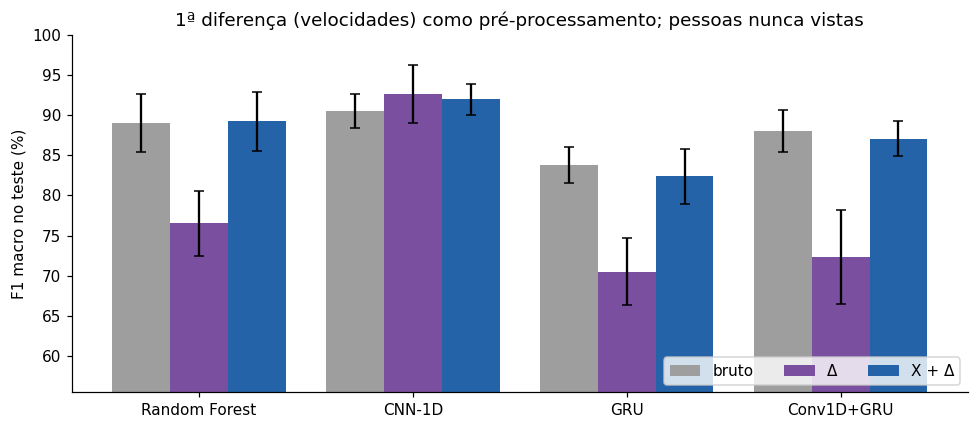

In [6]:
dif = pd.read_csv(ARQ_DIF)
base = dif[dif.tecnica == "bruto"].set_index(["modelo", "rodada", "semente"]).f1_macro
linhas = []
for modelo in MODELOS_B:
    for tecnica in VERSOES:
        v = dif[(dif.modelo == modelo) & (dif.tecnica == tecnica)].set_index(["modelo", "rodada", "semente"]).f1_macro
        linha = {"modelo": modelo, "técnica": tecnica, "F1 macro (%)": f"{100 * v.mean():.1f} ± {100 * v.std():.1f}"}
        if tecnica != "bruto":
            delta = (v - base.reindex(v.index)).dropna()
            p = wilcoxon(delta).pvalue if len(delta) >= 6 and np.any(delta != 0) else np.nan
            linha.update({"Δ vs bruto (p.p.)": f"{100 * delta.mean():+.1f}", "p (Wilcoxon)": f"{p:.3f}",
                          "pares que melhoraram": f"{int((delta > 0).sum())}/{len(delta)}"})
        linhas.append(linha)
tab_dif = pd.DataFrame(linhas).set_index(["modelo", "técnica"]).fillna("—")
display(tab_dif)
tab_dif.to_csv(RES / "06_tabela_diferencas.csv")

media = dif.groupby(["modelo", "tecnica"]).f1_macro.mean().unstack()[list(VERSOES)].reindex(MODELOS_B)
desvio = dif.groupby(["modelo", "tecnica"]).f1_macro.std().unstack()[list(VERSOES)].reindex(MODELOS_B)
fig, ax = plt.subplots(figsize=(9, 4))
cores = {"bruto": "#9e9e9e", "Δ": "#7B4FA0", "X + Δ": "#2563A8"}
for j, t in enumerate(VERSOES):
    ax.bar(np.arange(len(MODELOS_B)) + (j - 1) * 0.27, 100 * media[t], 0.27, yerr=100 * desvio[t], capsize=3,
           color=cores[t], label=t)
ax.set_xticks(range(len(MODELOS_B)), MODELOS_B); ax.set_ylabel("F1 macro no teste (%)")
ax.set_ylim(max(0, 100 * media.values.min() - 15), 100); ax.legend(ncol=3, loc="lower right")
ax.set_title("1ª diferença (velocidades) como pré-processamento; pessoas nunca vistas")
plt.tight_layout(); salvar_fig("diferencas_barras"); plt.show()

## 5. Síntese

### Parte A — calibração

| Rede | Escolhida na validação | F1 teste calibrado | F1 teste original (nb. 03) |
|---|---|---|---|
| CNN-1D | lr 3×10⁻⁴ | 91,1 ± 2,2 | 91,3 ± 2,5 |
| Conv1D+GRU | larga (2×) | 88,6 ± 1,7 | 89,0 ± 1,4 |
| WaveNet | original | 87,9 ± 2,5 | 87,9 ± 2,3 |
| GRU | larga (2×) | 83,9 ± 3,8 | 84,3 ± 3,7 |
| LSTM | dropout 0,5 | 78,0 ± 3,8 | 78,2 ± 3,1 |
| SimpleRNN | lr 3×10⁻⁴ | **53,9 ± 4,6** | 46,4 ± 10,2 |

1. **As configurações originais já estavam bem ajustadas.** Na validação, a configuração escolhida superou a original por no máximo 1 ponto em 4 das 6 redes (de 3 a 4 pontos só na LSTM e na SimpleRNN). No teste, as redes calibradas ficam a menos de 0,5 ponto das originais (dentro do ruído de reexecução, ~0,6 ponto).
2. **A única rede que ganha é a SimpleRNN** (+7,5 pontos, com o desvio caindo de ±10,2 para ±4,6): com a taxa de aprendizado menor, o treino fica mais estável, mas ela continua muito abaixo das redes com portas. O problema dela é estrutural (gradiente que some), e não de ajuste.
3. **A ordem entre as famílias não muda:** CNN-1D > Conv1D+GRU > WaveNet > GRU > LSTM > SimpleRNN. As conclusões do notebook 03 não dependem da escolha de hiperparâmetros.

### Parte B — 1ª diferença (velocidades)

| Modelo | bruto | Δ (só velocidades) | X + Δ |
|---|---|---|---|
| Random Forest | 89,0 | 76,5 (**−12,5**, p<0,001, 0/12) | 89,2 (+0,2) |
| CNN-1D | 90,5 | **92,6 (+2,2, p=0,034, 10/12)** | **91,9 (+1,5, p=0,009, 10/12)** |
| GRU | 83,8 | 70,5 (**−13,2**, p<0,001, 0/12) | 82,4 (−1,4) |
| Conv1D+GRU | 88,0 | 72,3 (**−15,6**, p<0,001, 0/12) | 87,1 (−0,9) |

*F1 macro (%), 4 rodadas × 3 sementes; Δ pareado contra o bruto da mesma máquina; teste de Wilcoxon; pares que melhoraram.*

4. **É a primeira técnica que melhora um modelo de forma consistente:** a CNN-1D com as velocidades sobe para **92,6%** (o melhor resultado do trabalho), melhorando em 10 das 12 rodadas × sementes. Com posição + velocidade, o ganho é menor (+1,5), porém o mais regular (p = 0,009).
5. **Por que só na CNN-1D.** A diferença remove o **deslocamento constante** de cada série: onde cada pessoa posiciona o corpo e as mãos, as proporções do corpo que a normalização não corrigiu. Sobra o **movimento**, que varia menos entre sinalizantes. É exatamente o problema identificado no notebook 01: a dificuldade não é a estacionariedade *dentro* da série, e sim a mudança de distribuição *entre* pessoas. A CNN-1D consegue aproveitar isso porque os seus filtros, somados no tempo pela média global (GAP), recompõem padrões de deslocamento a partir das velocidades: uma soma de velocidades é um deslocamento.
6. **Por que os outros pioram tanto com Δ.** Sem a posição absoluta, a **locação** do sinal (se a mão está perto do rosto, do peito, do ombro), que é um parâmetro fonológico da Libras, deixa de estar disponível diretamente. O Random Forest trata cada instante como uma coluna isolada e não consegue "integrar" as velocidades. As recorrentes, em tese, poderiam acumular as velocidades no estado, mas na prática perdem de 13 a 16 pontos.
7. **X + Δ é neutro fora da CNN.** Com a posição de volta, o RF, a GRU e a híbrida voltam ao nível do bruto (diferenças < 1,5 ponto, sem significância). Diferentemente da média móvel (notebook 04), dobrar os canais com velocidades não prejudica a GRU de forma significativa: as velocidades carregam informação útil, e não só ruído.

**Para o artigo:** a técnica que funciona é a mais simples e a que mais diretamente ataca a variação entre sinalizantes. As técnicas de "limpeza" do sinal (média móvel e FFT) não ajudam, porque o ruído do MediaPipe não é o gargalo. A 1ª diferença, com um ganho modesto, mas consistente, na melhor arquitetura, é a recomendação de pré-processamento do trabalho.


In [7]:
# Baixa os resultados quando o Drive não montou no Colab (a pasta /content é apagada quando o Colab desconecta)
if IN_COLAB and not DRIVE_OK:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/resultados_06", "zip", str(BASE), "resultados")
    files.download("/content/resultados_06.zip")
else:
    print("resultados gravados em", RES)

resultados gravados em /mnt/d/ProjetoMestrado/trabalho_series_temporais/resultados
